# Capstone decision story

*25 November 2026 · Official results through Round 9 · Week 10 prepared and unsubmitted*

The official record contains 175 shared starter measurements and 72 confirmed portal returns.

The aim throughout was to raise the best **measured** score on each function under a finite query budget. This is the evidence trail for the final capstone account. Each function opens with its argument, explains the changes worth defending, then gives the complete week-by-week decision ledger. The Week 10 decision follows the eight ledgers and records the two prepared query routes.

**Reading the record.** Week is the submission number and round is the corresponding official return. A Week 8 analysis starts from evidence through Round 7. Each ledger links to a saved decision or model record. Its returned scores and incumbent are rebuilt from the round result files and checked against the submitted coordinates. A snapshot can contain provisional model proposals as well as the final choice. The ledger follows the confirmed input. A star marks an improvement over the previous incumbent.

**Evidence available at the time.** The turning points cite the saved studies or dated decisions first. Current-cohort observations informed some historical choices, where identified. The 2024 archive and later refits are labelled as hindsight. They help interpret the results and stay outside the official score trail. [Submission log](../submissions/README.md) · [2024 evidence](../side-quests/historical-cohort-2024/README.md) · [Course data policy review](../docs/capstone-data-policy.md)

## Where each decision story leads

| Function | Main change in direction | Official best first reached |
| --- | --- | --- |
| 1 | Coverage gave way to a positive-source hypothesis | Round 8 |
| 2 | Broad sampling narrowed to an x1 band, then to a controlled x2 comparison | Round 6 |
| 3 | Weak surrogates gave way to a near-zero line anchored by a peer measurement | Round 8 |
| 4 | A positive local cluster prompted one-coordinate x3 tests | Round 7 |
| 5 | An early corner incumbent turned the problem into checking feasible directions | Round 2 |
| 6 | A neural-led return broke a plateau and motivated revisiting the x5 face | Round 7 |
| 7 | Repeated gains pulled queries to x1 = 0, where subsequent trials stalled | Round 6 |
| 8 | Interior refinement followed five corner trials, then a quadratic explained the campaign | Round 8 |

## Published checkpoints

The GitHub links pin the decision snapshots and the first published copy of each round result. Week 9 analysis was published before its final query selections and feedback. The latest local records are linked directly.

| Round | Feedback received in 2026 | Selection record | Official result |
| --- | --- | --- | --- |
| 1 | 5 Oct | [First-query proposal](https://github.com/AnthonyPWatts/imperial-capstone/blob/33a5a43694c72c1def99b2b226727147fc49611d/stage-2-bbo/results/first-query-proposals.md) | [GitHub bc9a1d1](https://github.com/AnthonyPWatts/imperial-capstone/blob/bc9a1d17e7ee3f5730cc97f81b401acc8d97564e/stage-2-bbo/submissions/round-01-results.json) |
| 2 | 8 Oct | [Week 2 notebook guide](README.md#previous-work-week-2) | [GitHub 45b669a](https://github.com/AnthonyPWatts/imperial-capstone/blob/45b669a202ab50506ad20916b0601819459945aa/stage-2-bbo/submissions/round-02-results.json) |
| 3 | 14 Oct | [Inputs](../submissions/Week_03/submissions.txt) | [GitHub 6def628](https://github.com/AnthonyPWatts/imperial-capstone/blob/6def62841ef039a19fb1029975d6152774c9464a/stage-2-bbo/submissions/round-03-results.json) |
| 4 | 23 Oct | [Confirmed Week 4 strategy](https://github.com/AnthonyPWatts/imperial-capstone/commit/c0c23aebdcf6c2aae50c90c250fa704309b1727e) | [GitHub 1499072](https://github.com/AnthonyPWatts/imperial-capstone/blob/1499072d682b37fc0c5698c5119d01e1cc603c12/stage-2-bbo/submissions/round-04-results.json) |
| 5 | 30 Oct | [Week 5 selection](../submissions/Week_05/README.md) | [GitHub f272ca8](https://github.com/AnthonyPWatts/imperial-capstone/blob/f272ca8bc05afe6b532eb6e882e55a4fdb6b8d6c/stage-2-bbo/submissions/round-05-results.json) |
| 6 | 2 Nov | [Week 6 selection](../submissions/Week_06/README.md) | [GitHub a497412](https://github.com/AnthonyPWatts/imperial-capstone/blob/a497412a5b9f88d59b7eeac52374ce6d35f14c06/stage-2-bbo/submissions/round-06-results.json) |
| 7 | 12 Nov | [Week 7 selection and saved forecasts](../submissions/Week_07/selection_review.ipynb) | [GitHub 89a6d9c](https://github.com/AnthonyPWatts/imperial-capstone/blob/89a6d9c3dcdb047254258cd9b8fe934ef162f413/stage-2-bbo/submissions/round-07-results.json) |
| 8 | 23 Nov | [Week 8 decisions](https://github.com/AnthonyPWatts/imperial-capstone/commit/9c0f0a6bcee2f7a69d88236a2123f39aa60e409e) and [F2 follow-up](https://github.com/AnthonyPWatts/imperial-capstone/commit/451a84bb663e7cac07b68a833604f3ef62e04a3a) | [GitHub 65b1077](https://github.com/AnthonyPWatts/imperial-capstone/blob/65b10777f75f466aa7d0c5cca6c80e6bfebe22f9/stage-2-bbo/submissions/round-08-results.json) |
| 9 | 25 Nov | [Week 9 selection](../submissions/Week_09/README.md) | [Local record](../submissions/round-09-results.json) |

The panels use raw score with an independent vertical scale per function. The blue step shows the best value seen from the starters through each round. Each dot is one portal return.

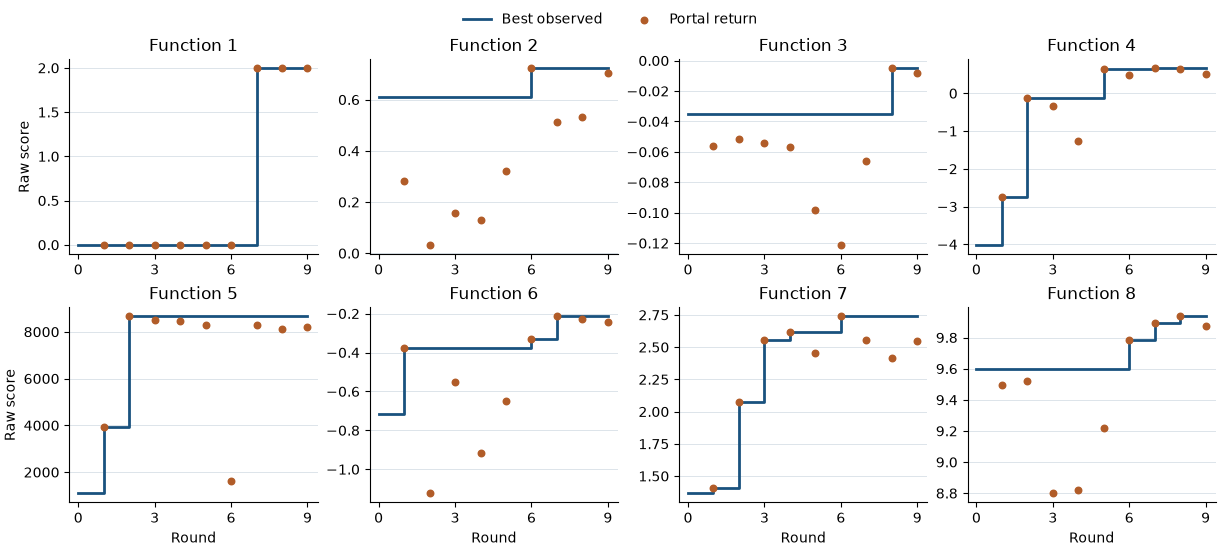

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, Markdown, display


current = Path.cwd().resolve()
for directory in (current, *current.parents):
    for candidate in (directory, directory / "stage-2-bbo"):
        if (candidate / "submissions" / "round-09-results.json").is_file():
            stage = candidate
            break
    else:
        continue
    break
else:
    raise FileNotFoundError("Open this notebook from the Stage 2 checkout with the round result records.")

confirmed = {function: [] for function in range(1, 9)}
for week in range(1, 10):
    path = stage / "submissions" / f"round-{week:02d}-results.json"
    record = json.loads(path.read_text(encoding="utf-8"))
    batch = (stage / "submissions" / f"Week_{week:02d}" / "submissions.txt").read_text(
        encoding="utf-8"
    ).splitlines()
    assert record["round"] == week and record["status"] == "evaluation_confirmed_by_results_email"
    assert len(batch) == len(record["results"]) == 8
    assert {row["function"] for row in record["results"]} == set(confirmed)
    for row in record["results"]:
        function = row["function"]
        previous = confirmed[function]
        assert batch[function - 1] == row["portal_input"]
        assert math.isfinite(row["output"])
        if previous:
            assert row["best_before"] == previous[-1]["best_after"]
        assert row["best_after"] == max(row["best_before"], row["output"])
        assert (row["best_after"] > row["best_before"]) == row["improved_incumbent"]
        previous.append(row)


def show_decisions(function, decisions):
    rows = confirmed[function]
    assert len(rows) == len(decisions)
    lines = [
        "| Week | Decision and source | Submitted input | Return | Best through round |",
        "| --- | --- | --- | ---: | ---: |",
        f"| Start | Shared starters | | | {rows[0]['best_before']:.10g} |",
    ]
    for week, (row, (decision, source)) in enumerate(zip(rows, decisions), 1):
        star = " ★" if row["improved_incumbent"] else ""
        lines.append(
            f"| {week} | {decision} [Evidence]({source}) |"
            f" `{row['portal_input']}` | {row['output']:.10g} | {row['best_after']:.10g}{star} |"
        )
    display(Markdown("\n".join(lines)))


fig, axes = plt.subplots(2, 4, figsize=(12.2, 5.5), layout="constrained")
for function, ax in zip(confirmed, axes.flat):
    rows = confirmed[function]
    scores = [row["output"] for row in rows]
    best = [rows[0]["best_before"], *(row["best_after"] for row in rows)]
    ax.step(range(10), best, where="post", color="#19527e", linewidth=2, label="Best observed")
    ax.scatter(range(1, 10), scores, color="#b15c28", s=22, zorder=3, label="Portal return")
    ax.set(title=f"Function {function}", xticks=[0, 3, 6, 9], xlim=(-0.35, 9.4))
    ax.grid(axis="y", color="#d7dfe6", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    if function in (1, 5):
        ax.set_ylabel("Raw score")
    if function > 4:
        ax.set_xlabel("Round")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncols=2, frameon=False)
image = BytesIO()
fig.savefig(image, format="png", dpi=100)
plt.close(fig)
display(Image(data=image.getvalue(), format="png", alt=(
    "Eight panels trace the best official score and each query return. The largest shifts "
    "include Function 1 in round 7, Function 3 in round 8 and Function 5 in round 2."
)))

## Function 1 — From coverage to a narrow positive source

**Overall story.** A broad search in two dimensions found almost no useful positive signal. A model of the shape of a source placed a query in the right neighbourhood, where three returns near 2 established a repeatable high region.

- **Weeks 1–5 · Keep the coverage plan while the score model has weak support.** The first query found −0.00551, a material negative response. Raw-output knowledge gradient (expected reduction in decision shortfall) was dominated by one large negative starter and did poorly on held-out scores. Four subsequent submissions used the fixed shortlist to fill gaps without letting effectively zero returns steer the search. The Week 5 signed-score and magnitude fits were experiments, while the submitted point completed the shortlist. [First-query rationale](../results/first-query-proposals.md) · [Coverage shortlist](Function_1/Week_02/exploration.ipynb) · [Week 5 predictive comparison](Function_1/Week_05/official/model_predictions.ipynb)
- **Weeks 6–7 · Switch from coverage to testing a source shape.** Week 6 followed the agreed central hunch using the signed-log GP mean with no exploration bonus. Its 2.17×10⁻¹⁴ was numerically best and still negligible as a source detection. The Week 7 studies first considered magnitude for locating activity, then selected a circular positive Gaussian fitted to the five strongest official positive readings. Five- and six-reading fits placed a peak nearby. Signed-log MAE favoured the source fit, while RMSE favoured the GP. Round 7 returned **1.99731436** at the source peak. The fit found a high-scoring place, and its conditional raw-height estimate of **0.7081** was far below the return. [Week 6 decision](../submissions/Week_06/README.md) · [Source comparison with saved outputs](Function_1/Week_07/official/source_shape_comparison.ipynb) · [Round 7 forecast comparison](../results/week-08-review.md)
- **Weeks 8–9 · Refine and check the extent of the high region.** Week 8 anchored the same source family to Round 7 and moved about 0.000385, giving the best official score, **1.99735570**. Week 9 used a distance-weighted 5-nearest-neighbour candidate inside the same narrow region and returned **1.99399319**. That small decline is informative about peak location. In hindsight the archive measured **1.999999999676** about 0.000742 from the incumbent. The local source is well supported, and these queries leave other regions sparsely tested. [Week 8 decision snapshot on GitHub](https://github.com/AnthonyPWatts/imperial-capstone/blob/9c0f0a6bcee2f7a69d88236a2123f39aa60e409e/stage-2-bbo/notebooks/Function_1/Week_08/official/model_predictions.ipynb) · [Week 9 comparison](../submissions/Week_09/README.md) · [Archive comparison](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_1/Week_10/weekly_review.ipynb)

In [2]:
show_decisions(1, [
    ('Cover a central gap using the benchmarked coverage policy.', '../results/first-query-proposals.md'),
    ('Start the fixed exploratory shortlist in the lower-left gap.', 'Function_1/Week_02/exploration.ipynb'),
    ('Take the saved shortlist point near the lower edge.', 'Function_1/Week_03/exploration.ipynb'),
    ('Take the saved shortlist point in the upper-left gap.', 'Function_1/Week_04/exploration.ipynb'),
    ('Complete the saved shortlist in the upper-right gap.', '../submissions/Week_05/README.md'),
    ('Use the signed-score mean for the central hunch.', '../submissions/Week_06/README.md'),
    ('Test the peak of the five-positive circular source.', 'Function_1/Week_07/official/source_shape_comparison.ipynb'),
    ('Refit the circular source to the new high reading and refine its peak.', 'Function_1/Week_08/official/model_predictions.ipynb'),
    ('Test the local 5-nearest-neighbour candidate.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | 7.710875115e-16 |
| 1 | Cover a central gap using the benchmarked coverage policy. [Evidence](../results/first-query-proposals.md) | `0.468429-0.435440` | -0.005509345554 | 7.710875115e-16 |
| 2 | Start the fixed exploratory shortlist in the lower-left gap. [Evidence](Function_1/Week_02/exploration.ipynb) | `0.153082-0.133955` | -4.057744972e-109 | 7.710875115e-16 |
| 3 | Take the saved shortlist point near the lower edge. [Evidence](Function_1/Week_03/exploration.ipynb) | `0.781859-0.025607` | 1.972811776e-200 | 7.710875115e-16 |
| 4 | Take the saved shortlist point in the upper-left gap. [Evidence](Function_1/Week_04/exploration.ipynb) | `0.129549-0.822189` | -9.545890352e-172 | 7.710875115e-16 |
| 5 | Complete the saved shortlist in the upper-right gap. [Evidence](../submissions/Week_05/README.md) | `0.912140-0.861783` | -1.38635891e-94 | 7.710875115e-16 |
| 6 | Use the signed-score mean for the central hunch. [Evidence](../submissions/Week_06/README.md) | `0.537942-0.522217` | 2.170912925e-14 | 2.170912925e-14 ★ |
| 7 | Test the peak of the five-positive circular source. [Evidence](Function_1/Week_07/official/source_shape_comparison.ipynb) | `0.627916-0.628953` | 1.997314363 | 1.997314363 ★ |
| 8 | Refit the circular source to the new high reading and refine its peak. [Evidence](Function_1/Week_08/official/model_predictions.ipynb) | `0.628208-0.629204` | 1.9973557 | 1.9973557 ★ |
| 9 | Test the local 5-nearest-neighbour candidate. [Evidence](../submissions/Week_09/README.md) | `0.627434-0.628714` | 1.993993185 | 1.9973557 |

## Function 2 — Find a promising x1 band, then put x2 back into the experiment

**Overall story.** Low-dimensional structure helped find a good region, but the fitted ridge was too reassuring about neighbouring inputs. The next useful evidence came from changing one coordinate at a time.

- **Weeks 1–5 · From a local model probe to broad coverage, then a reduced GP.** Week 1 trialled an upper-right point selected by a finer knowledge-gradient search. After that underperformed the **0.611205** starter, Weeks 2–4 used the saved coverage shortlist. Week 5 switched to an x1-only GP trained with the retained cohort rows because its RMSE on the same official held-out targets fell from **0.14578 to 0.12188**. In that fit x2 only broke ties geometrically. The return of **0.32251** was better than Weeks 1–4 but below the starter. [First-query rationale](../results/first-query-proposals.md) · [Coverage shortlist](Function_2/Week_02/exploration.ipynb) · [Week 5 comparison](Function_2/Week_05/report.md)
- **Weeks 6–8 · Verify the lower edge and see where the GP fails.** The Week 6 UCB trial used the near-zero x2 edge and returned **0.72305755** at x1 = 0.700520. Two official-fit lower-edge follow-ups moved x1 either side of that result and gave **0.51178** and **0.53187**. The Week 8 controlled comparison of upper confidence bound, expected improvement and probability of improvement made the assumptions visible. Its nominal decision GP predicted **0.73796** at the submitted point with observation SD **0.03825**. The large miss is evidence against trusting that particular uncertainty estimate for local decisions. [Week 6 selection](../submissions/Week_06/README.md) · [Week 7 local check](../submissions/Week_07/README.md) · [Week 8 acquisition comparison on GitHub](https://github.com/AnthonyPWatts/imperial-capstone/blob/451a84bb663e7cac07b68a833604f3ef62e04a3a/stage-2-bbo/notebooks/Function_2/Week_08/official/model_predictions.ipynb) · [Saved forecasts versus returns](../results/week-09-review.md)
- **Week 9 · Hold x1 fixed and test x2.** A peer scored **0.73624** at x1 = 0.71, x2 = 0.53. Holding the official-best x1 fixed and taking the peer's x2 gave **0.70297**, about **0.02009** below the near-zero-x2 measurement. That is one comparison. Later archive evidence is a reason to keep a second region in play. Eight evaluations at (0.5, 0.5) had a median of **0.79325**, and all eight exceeded the official best. Their spread also limits the conclusions from a single x2 trial. [Week 9 decision record](../submissions/Week_09/README.md) · [Archive comparison](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_2/Week_10/weekly_review.ipynb)

In [3]:
show_decisions(2, [
    ('Test the upper-right point from the refined knowledge-gradient study.', '../results/first-query-proposals.md'),
    ('Use the fixed coverage shortlist to sample the lower-left region.', 'Function_2/Week_02/exploration.ipynb'),
    ('Take the shortlist point on the high-x1, low-x2 side.', 'Function_2/Week_03/exploration.ipynb'),
    ('Take the shortlist point on the low-x1, high-x2 side.', 'Function_2/Week_04/exploration.ipynb'),
    ('Use the retained-peer x1-only GP and its spacing tie-break for x2.', '../submissions/Week_05/README.md'),
    ('Test the lower edge near x1 = 0.70 with GP upper confidence bound.', '../submissions/Week_06/README.md'),
    ('Move x1 upward from the new incumbent while keeping x2 near zero.', '../submissions/Week_07/README.md'),
    ('Try lower x1 on the same edge and compare three acquisition rules.', 'Function_2/Week_08/official/model_predictions.ipynb'),
    ('Keep the best x1 and test the published x2 = 0.53 setting.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | 0.6112052158 |
| 1 | Test the upper-right point from the refined knowledge-gradient study. [Evidence](../results/first-query-proposals.md) | `0.774999-0.949999` | 0.2834440433 | 0.6112052158 |
| 2 | Use the fixed coverage shortlist to sample the lower-left region. [Evidence](Function_2/Week_02/exploration.ipynb) | `0.228234-0.066644` | 0.03109504446 | 0.6112052158 |
| 3 | Take the shortlist point on the high-x1, low-x2 side. [Evidence](Function_2/Week_03/exploration.ipynb) | `0.835565-0.232911` | 0.156096372 | 0.6112052158 |
| 4 | Take the shortlist point on the low-x1, high-x2 side. [Evidence](Function_2/Week_04/exploration.ipynb) | `0.179540-0.808737` | 0.1311943186 | 0.6112052158 |
| 5 | Use the retained-peer x1-only GP and its spacing tie-break for x2. [Evidence](../submissions/Week_05/README.md) | `0.636151-0.495605` | 0.3225077077 | 0.6112052158 |
| 6 | Test the lower edge near x1 = 0.70 with GP upper confidence bound. [Evidence](../submissions/Week_06/README.md) | `0.700520-0.000114` | 0.7230575456 | 0.7230575456 ★ |
| 7 | Move x1 upward from the new incumbent while keeping x2 near zero. [Evidence](../submissions/Week_07/README.md) | `0.716870-0.000000` | 0.5117797787 | 0.7230575456 |
| 8 | Try lower x1 on the same edge and compare three acquisition rules. [Evidence](Function_2/Week_08/official/model_predictions.ipynb) | `0.689813-0.000000` | 0.5318742667 | 0.7230575456 |
| 9 | Keep the best x1 and test the published x2 = 0.53 setting. [Evidence](../submissions/Week_09/README.md) | `0.700520-0.530000` | 0.7029662814 | 0.7230575456 |

## Function 3 — A stronger measurement made the search one-dimensional locally

**Overall story.** Broad and model-led experiments left the shared starter best intact for seven rounds. A near-zero peer measurement gave a firmer starting point for a controlled test than the fitted means.

- **Weeks 1–4 · Explore while predictive support is weak.** The first local trial explored a region around two relatively good starters, but the best fitted model had slightly worse held-out RMSE than the mean baseline. Weeks 2–4 therefore used the broad, fixed shortlist. All four returns were around −0.05 to −0.06, with **−0.03483531** still best from the starters. [First-query rationale](../results/first-query-proposals.md) · [Coverage shortlist](Function_3/Week_02/exploration.ipynb)
- **Weeks 5–7 · Better held-out error gave a reason to try the GP, with limited payoff at the selected points.** The retained-peer GP improved paired official-target RMSE from **0.07570 to 0.04785**, with slightly worse MAE. The two low-x3 candidates returned **−0.09837** and **−0.12142**. After the second miss, Week 7 revisited a mean-led point near the official incumbent. Its saved GP mean was **−0.03289**, while the result was **−0.06587**. The Week 5 reflection had also found zero recall on the five good points for one fitted RBF classifier, limiting that idea as an alternative at the time. [Week 5 selected fit](Function_3/Week_05/report.md) · [Week 5 classifier study](../results/week-05-surrogate-comparison.md) · [Week 7 saved forecast](../submissions/Week_07/README.md)
- **Weeks 8–9 · Transfer the high-scoring slice, then test between the endpoints.** Aby's **−0.00014031** at (0.52, 0.55, 0.45) supplied an anchor. Holding x1 and x3 fixed while raising x2 to 0.61 gave **−0.00495200**, the first improvement. The saved Week 8 two-query comparison slightly favoured that order across the stated sensitivity checks. Week 9 tested x2 = 0.58 to see how the high-scoring endpoints joined. It returned **−0.00810936**, below both. The evidence supports staying near the slice and measuring its profile. A zero ceiling and a smoothly improving path between the points remain hypotheses. Later archived near-zero results support the neighbourhood. [Archive comparison](../side-quests/historical-cohort-2024/README.md) · [Week 8 lookahead and decision on GitHub](https://github.com/AnthonyPWatts/imperial-capstone/blob/9c0f0a6bcee2f7a69d88236a2123f39aa60e409e/stage-2-bbo/notebooks/Function_3/Week_08/official/model_predictions.ipynb) · [Week 9 midpoint rationale](../submissions/Week_09/README.md) · [Aby's published history](https://github.com/originalaby/imperial-ml-capstone/blob/b72a6be9283bb874a8d4b9856ba6f5d352da3375/data/queries.csv)


[Latest function assessment and remaining-budget plan](Function_3/Week_10/weekly_review.ipynb)

In [4]:
show_decisions(3, [
    ('Probe a region near two relatively good starter measurements.', '../results/first-query-proposals.md'),
    ('Start the saved broad-coverage shortlist.', 'Function_3/Week_02/exploration.ipynb'),
    ('Continue the shortlist at high x2 and x3.', 'Function_3/Week_03/exploration.ipynb'),
    ('Complete the Week 2 shortlist with another high-x3 point.', 'Function_3/Week_04/exploration.ipynb'),
    ('Use the retained-peer GP with lower paired RMSE and test near x3 = 0.', '../submissions/Week_05/README.md'),
    ('Retain the exploratory GP proposal near x3 = 0.', '../submissions/Week_06/README.md'),
    ('Return to a mean-led candidate near the official best.', '../submissions/Week_07/README.md'),
    ("Hold Aby's x1 and x3 fixed and raise x2 to 0.61.", 'Function_3/Week_08/official/model_predictions.ipynb'),
    ('Test x2 = 0.58 between the official and published high returns.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | -0.03483531335 |
| 1 | Probe a region near two relatively good starter measurements. [Evidence](../results/first-query-proposals.md) | `0.335102-0.257540-0.459461` | -0.05643115939 | -0.03483531335 |
| 2 | Start the saved broad-coverage shortlist. [Evidence](Function_3/Week_02/exploration.ipynb) | `0.954524-0.819470-0.042163` | -0.05128239634 | -0.03483531335 |
| 3 | Continue the shortlist at high x2 and x3. [Evidence](Function_3/Week_03/exploration.ipynb) | `0.352320-0.930799-0.849849` | -0.05420857469 | -0.03483531335 |
| 4 | Complete the Week 2 shortlist with another high-x3 point. [Evidence](Function_3/Week_04/exploration.ipynb) | `0.903842-0.268903-0.875200` | -0.05664212418 | -0.03483531335 |
| 5 | Use the retained-peer GP with lower paired RMSE and test near x3 = 0. [Evidence](../submissions/Week_05/README.md) | `0.658460-0.558234-0.006012` | -0.09836885375 | -0.03483531335 |
| 6 | Retain the exploratory GP proposal near x3 = 0. [Evidence](../submissions/Week_06/README.md) | `0.721213-0.830963-0.001845` | -0.1214168015 | -0.03483531335 |
| 7 | Return to a mean-led candidate near the official best. [Evidence](../submissions/Week_07/README.md) | `0.495233-0.568579-0.295191` | -0.06587383725 | -0.03483531335 |
| 8 | Hold Aby's x1 and x3 fixed and raise x2 to 0.61. [Evidence](Function_3/Week_08/official/model_predictions.ipynb) | `0.520000-0.610000-0.450000` | -0.004952000822 | -0.004952000822 ★ |
| 9 | Test x2 = 0.58 between the official and published high returns. [Evidence](../submissions/Week_09/README.md) | `0.520000-0.580000-0.450000` | -0.008109357492 | -0.004952000822 |

## Function 4 — Locate the positive hill, then isolate x3

**Overall story.** Models helped shrink the search around a high-scoring region. Once there were several positive returns, one-coordinate comparisons gave clearer local evidence than the GP's predicted heights.

- **Weeks 1–5 · Follow model-led combinations until a positive return anchors the hill.** The initial comparison supported modelling, with best held-out RMSE **82.7%** below the mean baseline. Round 1 raised the starter best from **−4.02554 to −2.73816** and Round 2 reached **−0.12992**. Two more GP-led points fell back. For Week 5, adding the retained cohort rows worsened paired validation, so the official GP's winner on the common candidate pool was selected. It returned **0.65013**, the first positive submission. [Initial rationale](../results/first-query-proposals.md) · [Week 4 saved strategy](Function_4/Week_04/model_predictions.ipynb) · [Week 5 comparison](Function_4/Week_05/report.md)
- **Weeks 6–8 · Give positive measured neighbours more influence.** Round 6 returned **0.48991** near the new incumbent, despite a negative saved GP mean. In Week 7 the peer score of **0.71215** motivated changing only x3 of the Round 5 point from 0.408855 to 0.364200. That raised the official best to **0.66609** against a fitted GP mean of **−0.28422**. Week 8 ran a second x3-only test along the peer's other three coordinates, changing 0.364200 to 0.377000. The result, **0.63827**, was lower than the peer endpoint, but supports a high neighbourhood. These comparisons test x3 in two distinct settings of the other coordinates. [Week 7 selection](../submissions/Week_07/README.md) · [Week 8 x3 decision on GitHub](https://github.com/AnthonyPWatts/imperial-capstone/blob/9c0f0a6bcee2f7a69d88236a2123f39aa60e409e/stage-2-bbo/notebooks/Function_4/Week_08/official/model_predictions.ipynb) · [Peer notebook](https://github.com/kosina/bbocapstone/blob/8db82a121efe015d94cb01d19d1439adf21287a7/capstone_bbo.ipynb)
- **Week 9 · Give the original official GP another local test.** The Matérn comparator assigned the original GP's point a higher mean than its own UCB selection. The submitted multi-coordinate move returned **0.50791**. It adds another positive measurement and leaves the precise local peak unresolved. The 2024 score of **0.69207** in the wider cluster adds retrospective support for a hill in this region. [Week 9 model comparison](../results/week-09-official-alternatives.md) · [Final selection](../submissions/Week_09/README.md) · [Archive comparison](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_4/Week_10/weekly_review.ipynb)

In [5]:
show_decisions(4, [
    ('Test a modelled combination near the better starter settings.', '../results/first-query-proposals.md'),
    ('Refine with the GP in the developing high-score region.', 'Function_4/Week_02/model_predictions.ipynb'),
    ('Continue the GP-led local search after the strong Round 2 gain.', 'Function_4/Week_03/model_predictions.ipynb'),
    ('Retain the saved model-led plan for another nearby combination.', 'Function_4/Week_04/model_predictions.ipynb'),
    ('Use the official GP common-pool winner after paired validation.', '../submissions/Week_05/README.md'),
    ('Take a nearby GP-UCB test after the first positive return.', '../submissions/Week_06/README.md'),
    ('Change x3 alone from the official incumbent using the high peer setting.', '../submissions/Week_07/README.md'),
    ("Change x3 alone along the high peer point's other coordinates.", 'Function_4/Week_08/official/model_predictions.ipynb'),
    ('Test the preferred original official GP point in the positive cluster.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | -4.025542282 |
| 1 | Test a modelled combination near the better starter settings. [Evidence](../results/first-query-proposals.md) | `0.377878-0.477308-0.239218-0.435290` | -2.738157434 | -2.738157434 ★ |
| 2 | Refine with the GP in the developing high-score region. [Evidence](Function_4/Week_02/model_predictions.ipynb) | `0.445520-0.390792-0.374106-0.377372` | -0.1299181452 | -0.1299181452 ★ |
| 3 | Continue the GP-led local search after the strong Round 2 gain. [Evidence](Function_4/Week_03/model_predictions.ipynb) | `0.459127-0.368781-0.430162-0.390645` | -0.3479650985 | -0.1299181452 |
| 4 | Retain the saved model-led plan for another nearby combination. [Evidence](Function_4/Week_04/model_predictions.ipynb) | `0.354513-0.376712-0.378960-0.488593` | -1.259160309 | -0.1299181452 |
| 5 | Use the official GP common-pool winner after paired validation. [Evidence](../submissions/Week_05/README.md) | `0.419096-0.406060-0.408855-0.426466` | 0.6501304055 | 0.6501304055 ★ |
| 6 | Take a nearby GP-UCB test after the first positive return. [Evidence](../submissions/Week_06/README.md) | `0.408963-0.412546-0.416464-0.438393` | 0.4899061386 | 0.6501304055 |
| 7 | Change x3 alone from the official incumbent using the high peer setting. [Evidence](../submissions/Week_07/README.md) | `0.419096-0.406060-0.364200-0.426466` | 0.6660895989 | 0.6660895989 ★ |
| 8 | Change x3 alone along the high peer point's other coordinates. [Evidence](Function_4/Week_08/official/model_predictions.ipynb) | `0.407459-0.418058-0.377000-0.420348` | 0.6382713729 | 0.6660895989 |
| 9 | Test the preferred original official GP point in the positive cluster. [Evidence](../submissions/Week_09/README.md) | `0.391921-0.432079-0.420229-0.427165` | 0.507907947 | 0.6660895989 |

## Function 5 — An early corner win changed the job from finding a peak to testing it

**Overall story.** This was the quickest strong result. Most of the later queries asked which directions away from the upper corner lose score. One deliberate excursion tested how much performance remained on another part of the upper face.

- **Weeks 1–2 · Follow a strong signal to the permitted corner.** The initial study targeted a combination with high x2, x3 and x4, and its larger candidate pool changed the exact proposal. The return of **3,933.15** substantially exceeded the starter **1,088.86**. Week 2 used the GP-led adaptive search and put all four coordinates at the six-decimal upper bound. The return of **8,662.40500** remains the official best. [First-query rationale](../results/first-query-proposals.md) · [Week 2 saved GP study](Function_5/Week_02/model_predictions.ipynb)
- **Weeks 3–6 · Check the immediate vicinity, then spend one query on information.** The next three near-corner trials were lower. Week 5 introduced an explicit 0.02 input spacing rule and isolated x4. The Week 5 retrospective found positive neural derivatives on all four axes at the corner and no accepted feasible ascent step in that fit. In Week 6 both the GP and neural models preferred the saved local x3 alternative. The decision deliberately deferred it and tested x1 = x2 = 0 with x3 and x4 still high. The result, **1,616.63**, beat the starters and was far below the corner. Changing x1 and x2 together left their individual effects unresolved. [Week 5 selection](../submissions/Week_05/README.md) · [Saved surrogate experiment](Function_5/Week_05/surrogate-study/report.md) · [Week 6 change of plan](Function_5/Week_06/report.md)
- **Weeks 7–9 · Finish one-coordinate comparisons.** Reducing x3, then x2, then x1 alone cost **379.34**, **563.23** and **439.20** points respectively at the tested step sizes. The earlier x4 trial cost **378.58**. These are finite differences at different step sizes, so the losses support the corner without ranking global feature importance. The 2024 data independently reproduce the same best at the portal-valid corner. Evidence for this incumbent is strong, with untested combinations still possible elsewhere. [Week 7 choice](../submissions/Week_07/README.md) · [Week 8 x2 choice](Function_5/Week_08/model_predictions.ipynb) · [Week 9 x1 choice](../submissions/Week_09/README.md) · [Archive comparison](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_5/Week_10/weekly_review.ipynb)

In [6]:
show_decisions(5, [
    ('Probe high x2, x3 and x4 using the larger decision-risk candidate pool.', '../results/first-query-proposals.md'),
    ('Put all four inputs at the allowed upper corner.', 'Function_5/Week_02/model_predictions.ipynb'),
    ('Vary x1 and x2 slightly with x3 and x4 still at the upper bound.', 'Function_5/Week_03/model_predictions.ipynb'),
    ('Continue the GP-led check near the upper corner.', 'Function_5/Week_04/model_predictions.ipynb'),
    ('Apply 0.02 spacing and reduce x4 alone.', '../submissions/Week_05/README.md'),
    ('Defer the x3 probe and test x1 = x2 = 0 on the upper x3/x4 face.', '../submissions/Week_06/README.md'),
    ('Return to the corner and reduce x3 alone.', '../submissions/Week_07/README.md'),
    ('Reduce x2 alone using the refreshed local candidate comparison.', 'Function_5/Week_08/model_predictions.ipynb'),
    ('Reduce x1 alone at the point shared by the original GP and blend.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | 1088.859618 |
| 1 | Probe high x2, x3 and x4 using the larger decision-risk candidate pool. [Evidence](../results/first-query-proposals.md) | `0.375048-0.953644-0.999999-0.999999` | 3933.145724 | 3933.145724 ★ |
| 2 | Put all four inputs at the allowed upper corner. [Evidence](Function_5/Week_02/model_predictions.ipynb) | `0.999999-0.999999-0.999999-0.999999` | 8662.405001 | 8662.405001 ★ |
| 3 | Vary x1 and x2 slightly with x3 and x4 still at the upper bound. [Evidence](Function_5/Week_03/model_predictions.ipynb) | `0.996065-0.996814-0.999999-0.999999` | 8525.753289 | 8662.405001 |
| 4 | Continue the GP-led check near the upper corner. [Evidence](Function_5/Week_04/model_predictions.ipynb) | `0.999515-0.989282-0.999999-0.999999` | 8449.982375 | 8662.405001 |
| 5 | Apply 0.02 spacing and reduce x4 alone. [Evidence](../submissions/Week_05/README.md) | `0.999999-0.999999-0.999999-0.979636` | 8283.828104 | 8662.405001 |
| 6 | Defer the x3 probe and test x1 = x2 = 0 on the upper x3/x4 face. [Evidence](../submissions/Week_06/README.md) | `0.000000-0.000000-0.999999-0.999999` | 1616.625747 | 8662.405001 |
| 7 | Return to the corner and reduce x3 alone. [Evidence](../submissions/Week_07/README.md) | `0.999999-0.999999-0.979593-0.999999` | 8283.061544 | 8662.405001 |
| 8 | Reduce x2 alone using the refreshed local candidate comparison. [Evidence](Function_5/Week_08/model_predictions.ipynb) | `0.999999-0.969053-0.999999-0.999999` | 8099.179959 | 8662.405001 |
| 9 | Reduce x1 alone at the point shared by the original GP and blend. [Evidence](../submissions/Week_09/README.md) | `0.976212-0.999999-0.999999-0.999999` | 8223.20909 | 8662.405001 |

## Function 6 — A neural-led local move broke the plateau; the x5 face still has a rival

**Overall story.** The first query found a promising region. A focused model change produced two more gains there. An off-face trial and subsequent historical evidence left the broader peak question open.

- **Weeks 1–5 · Confirm a useful region, then spend four queries exploring around it.** The first proposal retained relatively high x4 and low x5 while varying the other inputs, improving the starter from **−0.71427 to −0.37869**. The ensuing GP-UCB trials were exploratory. For instance, the Week 3 prediction was **−0.61718**, already below the incumbent, with a different candidate at each tested weight. The actual return of **−0.55138** left the first-round best intact. All four follow-ups were lower. [Initial rationale](../results/first-query-proposals.md) · [Week 3 saved model](Function_6/Week_03/model_predictions.ipynb) · [Week 5 selection](../submissions/Week_05/README.md)
- **Weeks 6–8 · Use a narrow neural experiment and then check the x5 = 0 face.** Neural LOO RMSE was **0.32605** versus the official GP's **0.33965**. That modest gain, worse error on the weekly subset and model disagreement made the substitution a single focused test. The neural point was closer to the existing best than the exploratory GP proposal. Round 6 improved to **−0.32819** and another neural-led point cross-checked by the GP improved to **−0.21396**. Both used x5 = 0. A different point on that face then gave **−0.22858**. The Round 7 neural mean was **−0.34130**, so the model helped lead to a good location without forecasting the improvement. [Week 6 rationale](../submissions/Week_06/README.md) · [Week 7 rationale](../submissions/Week_07/README.md) · [Week 8 local lookahead](Function_6/Week_08/model_predictions.ipynb)
- **Week 9 · Let a better replay model challenge the boundary.** Support vector regression had the lowest error on the eight later official returns in the Week 9 comparison. Its candidate was near the best published peer and moved to x5 = 0.072632. The new score of **−0.24135** stayed close to the face results and below the incumbent. Several archived points near x5 ≈ 0.114 were substantially higher, with a best of **−0.00614**. That is a distinct interior challenger, beyond the one off-face test already run. [Week 9 alternative models](../results/week-09-official-alternatives.md) · [Final selection](../submissions/Week_09/README.md) · [Archive comparison](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_6/Week_10/weekly_review.ipynb)

In [7]:
show_decisions(6, [
    ('Retain relatively high x4 and low x5 while varying the other coordinates.', '../results/first-query-proposals.md'),
    ('Try a GP-led point on the x5 = 0 face.', 'Function_6/Week_02/model_predictions.ipynb'),
    ('Retain GP-UCB at 1.96 for an uncertainty-led exploratory query.', 'Function_6/Week_03/model_predictions.ipynb'),
    ('Retain the model-led strategy for a different x5 = 0 setting.', 'Function_6/Week_04/model_predictions.ipynb'),
    ('Try the full-space GP-UCB candidate, with a below-incumbent mean.', '../submissions/Week_05/README.md'),
    ('Substitute the nearby neural candidate on x5 = 0 for one trial.', '../submissions/Week_06/README.md'),
    ('Take a further neural-led step on x5 = 0 with a GP cross-check.', '../submissions/Week_07/README.md'),
    ('Stay on x5 = 0 and test the agreed local lookahead starting point.', 'Function_6/Week_08/model_predictions.ipynb'),
    ('Test the SVR candidate near the best published peer and slightly off the face.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | -0.7142649478 |
| 1 | Retain relatively high x4 and low x5 while varying the other coordinates. [Evidence](../results/first-query-proposals.md) | `0.344331-0.260596-0.575965-0.745346-0.066311` | -0.3786912545 | -0.3786912545 ★ |
| 2 | Try a GP-led point on the x5 = 0 face. [Evidence](Function_6/Week_02/model_predictions.ipynb) | `0.207231-0.508312-0.102836-0.929415-0.000000` | -1.124280793 | -0.3786912545 |
| 3 | Retain GP-UCB at 1.96 for an uncertainty-led exploratory query. [Evidence](Function_6/Week_03/model_predictions.ipynb) | `0.361714-0.068821-0.707704-0.977540-0.103049` | -0.5513794233 | -0.3786912545 |
| 4 | Retain the model-led strategy for a different x5 = 0 setting. [Evidence](Function_6/Week_04/model_predictions.ipynb) | `0.283620-0.019172-0.689432-0.559026-0.000000` | -0.9170702534 | -0.3786912545 |
| 5 | Try the full-space GP-UCB candidate, with a below-incumbent mean. [Evidence](../submissions/Week_05/README.md) | `0.310003-0.303475-0.617318-0.965962-0.334839` | -0.6515720614 | -0.3786912545 |
| 6 | Substitute the nearby neural candidate on x5 = 0 for one trial. [Evidence](../submissions/Week_06/README.md) | `0.398303-0.269220-0.627336-0.768441-0.000000` | -0.3281923879 | -0.3281923879 ★ |
| 7 | Take a further neural-led step on x5 = 0 with a GP cross-check. [Evidence](../submissions/Week_07/README.md) | `0.414821-0.260324-0.607614-0.728412-0.000000` | -0.2139595403 | -0.2139595403 ★ |
| 8 | Stay on x5 = 0 and test the agreed local lookahead starting point. [Evidence](Function_6/Week_08/model_predictions.ipynb) | `0.458028-0.356761-0.615581-0.686191-0.000000` | -0.228584024 | -0.2139595403 |
| 9 | Test the SVR candidate near the best published peer and slightly off the face. [Evidence](../submissions/Week_09/README.md) | `0.445816-0.323600-0.551644-0.755918-0.072632` | -0.241345937 | -0.2139595403 |

## Function 7 — A productive descent to x1 = 0 turned into a boundary plateau

**Overall story.** Successive local gains made the boundary a reasonable place to spend queries. Once there, changing other coordinates or the surrogate gave smaller returns. Published results later showed why the face was an incomplete search.

- **Weeks 1–4 · Use early improvements to keep local refinement.** The first submission raised x4 by 0.1 at the best starter, moving the score from **1.36497 to 1.40576** despite weak initial predictive support. GP-led follow-ups then produced **2.07522**, **2.55242** and **2.61897** as the selected points moved towards x1 = 0. The Week 3 study retained UCB at 1.96 after a **45.8%** held-out RMSE reduction versus the mean baseline. Its forecast of **1.99233** was below the previous incumbent, and the actual gain strengthened the case for that neighbourhood. Several coordinates moved together during this phase. [First-query rationale](../results/first-query-proposals.md) · [Week 3 saved model](Function_7/Week_03/model_predictions.ipynb) · [Round 4 record](../submissions/round-04-results.json)
- **Weeks 5–8 · Commit to the x1 face and learn where further refinement stalls.** The first x1 = 0 point gave **2.45856**. The Week 6 GP-UCB trial then reached **2.73938**. Its fitted mean was below the incumbent at the time, with the local search and uncertainty bonus supplying the reason to try it. Week 7 mainly reduced x4 and gave **2.55902**. Week 8 selected another face point after the official-weighted two-query comparison and returned **2.41389**. The results justify the face as a productive region but do not isolate the effect of driving x1 to zero. [Week 6 selection](../submissions/Week_06/README.md) · [Week 7 selection](../submissions/Week_07/README.md) · [Week 8 lookahead](Function_7/Week_08/model_predictions.ipynb)
- **Week 9 · Change the surrogate while staying on the same face.** Kernel ridge supplied a point near the three best official returns. The original GP, which scored better on the later returns, preferred its mean to its own UCB point. Round 9 gave **2.54889**, so the official best held. In hindsight archived scores above **3.3** cluster at x1 ≈ 0.21–0.23 and an independent campaign reached **3.32237** near x1 = 0.20. That evidence challenges the broader search boundary without undoing the measured gains on the face. [Week 9 selection](../submissions/Week_09/README.md) · [Archive and independent campaign](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_7/Week_10/weekly_review.ipynb)

In [8]:
show_decisions(7, [
    ('Increase x4 by 0.1 at the leading starter.', '../results/first-query-proposals.md'),
    ('Continue model-led refinement after the first gain.', 'Function_7/Week_02/model_predictions.ipynb'),
    ("Use the local GP-UCB candidate after Round 2's gain.", 'Function_7/Week_03/model_predictions.ipynb'),
    ('Retain the saved GP strategy very close to x1 = 0.', 'Function_7/Week_04/model_predictions.ipynb'),
    ('Use UCB to refine the Round 4 region at x1 = 0.', '../submissions/Week_05/README.md'),
    ('Test another local GP-UCB point on that face.', '../submissions/Week_06/README.md'),
    ('Mostly lower x4 at the newest incumbent on the face.', '../submissions/Week_07/README.md'),
    ('Use the official-weighted two-query comparison on the same face.', 'Function_7/Week_08/model_predictions.ipynb'),
    ('Try the kernel ridge point in the boundary basin with a GP cross-check.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | 1.364968304 |
| 1 | Increase x4 by 0.1 at the leading starter. [Evidence](../results/first-query-proposals.md) | `0.057896-0.491672-0.247422-0.318118-0.420428-0.730970` | 1.405759286 | 1.405759286 ★ |
| 2 | Continue model-led refinement after the first gain. [Evidence](Function_7/Week_02/model_predictions.ipynb) | `0.015118-0.386113-0.305380-0.283890-0.363300-0.714745` | 2.075221839 | 2.075221839 ★ |
| 3 | Use the local GP-UCB candidate after Round 2's gain. [Evidence](Function_7/Week_03/model_predictions.ipynb) | `0.018718-0.312926-0.370268-0.285721-0.308321-0.695670` | 2.552417653 | 2.552417653 ★ |
| 4 | Retain the saved GP strategy very close to x1 = 0. [Evidence](Function_7/Week_04/model_predictions.ipynb) | `0.002902-0.196293-0.424115-0.271557-0.287658-0.746916` | 2.618968215 | 2.618968215 ★ |
| 5 | Use UCB to refine the Round 4 region at x1 = 0. [Evidence](../submissions/Week_05/README.md) | `0.000000-0.257992-0.509505-0.318385-0.371190-0.725014` | 2.458556774 | 2.618968215 |
| 6 | Test another local GP-UCB point on that face. [Evidence](../submissions/Week_06/README.md) | `0.000000-0.135108-0.370684-0.306265-0.311144-0.649736` | 2.739375118 | 2.739375118 ★ |
| 7 | Mostly lower x4 at the newest incumbent on the face. [Evidence](../submissions/Week_07/README.md) | `0.000000-0.135660-0.364055-0.203076-0.342712-0.663441` | 2.55901786 | 2.739375118 |
| 8 | Use the official-weighted two-query comparison on the same face. [Evidence](Function_7/Week_08/model_predictions.ipynb) | `0.000000-0.192025-0.266625-0.295966-0.243731-0.645462` | 2.413890074 | 2.739375118 |
| 9 | Try the kernel ridge point in the boundary basin with a GP cross-check. [Evidence](../submissions/Week_09/README.md) | `0.000000-0.145572-0.392685-0.242554-0.346193-0.742781` | 2.548887834 | 2.739375118 |

## Function 8 — Leave the corners, refine the interior, then explain the whole surface

**Overall story.** Early fits predicted well on held-out data but kept prioritising corners. A change to a non-corner query unlocked a run of gains. The final structural explanation suggests a specific peak that is still unmeasured officially.

- **Weeks 1–5 · Model-led corner exploration fails to beat the best starter.** The initial analysis found strong additive predictive structure. Uncertainty helped choose extreme configurations, with Week 3's best GP improving held-out RMSE over ridge (**0.2874** versus **0.4838**) despite its below-incumbent mean at the proposal. Neither the two early near-9.5 returns nor the later corners beat the starter **9.598482**. The fifth corner was chosen after comparing full-space and local candidate pools and coverage. Predictive fit on sampled observations gave only indirect support for the corners. [First-query rationale](../results/first-query-proposals.md) · [Week 3 saved GP](Function_8/Week_03/model_predictions.ipynb) · [Week 5 selection](../submissions/Week_05/README.md)
- **Weeks 6–8 · Break from corners and exploit measured gains.** Week 6 tested a full-input non-corner point for which both saved model means cleared the incumbent, although the GP's projected gain was smaller than its validation error. It gave **9.78294**. Week 7 screened a ±0.15 per-coordinate box around that point for candidates both models expected to improve, then used the best GP mean in that screen. It returned **9.89327**. Week 8 used local candidate boxes around the best own and peer points and a two-query comparison. The selected point returned **9.93677**, very close to the archived weekly GP mean of **9.93489**. [Week 6 model review](Function_8/Week_06/report.md) · [Week 7 local screen](../submissions/Week_07/README.md) · [Week 8 decision](Function_8/Week_08/model_predictions.ipynb) · [Round 8 replay](../results/week-09-review.md)
- **Week 9 and hindsight · A local model alternative gives way to an explicit surface hypothesis.** Week 9 used a Matérn GP candidate with better replay error and closer to the incumbent than either saved GP corner. It returned **9.87427**. After that result, the archive prompted a structural check. A separable concave quadratic fitted to the **40 official starters** predicts all nine later official returns with maximum absolute error **1.95×10⁻¹⁴**. Its stationary point, (0.10, 0.15, 0.13, 0.15, 0.80, 0.50, 0.20, 0.60), is portal-valid and predicts **10.0**, also independently reported at that point. This is the unique global maximum of the fitted quadratic. The official measured best remains **9.93677**, and choosing the model form after seeing later evidence makes the replay retrospective. [Week 9 selection](../submissions/Week_09/README.md) · [Executed structural check](Function_8/Week_10/weekly_review.ipynb) · [Archive and independent result](../side-quests/historical-cohort-2024/README.md)


[Latest function assessment and remaining-budget plan](Function_8/Week_10/weekly_review.ipynb)

In [9]:
show_decisions(8, [
    ('Test the model-selected corner with x5 high and the other coordinates low.', '../results/first-query-proposals.md'),
    ('Try a corner with both x5 and x8 high.', 'Function_8/Week_02/model_predictions.ipynb'),
    ('Follow the retained GP-UCB policy to a different corner.', 'Function_8/Week_03/model_predictions.ipynb'),
    ('Continue the saved model-led corner strategy.', 'Function_8/Week_04/model_predictions.ipynb'),
    ('Test another extrapolative corner after comparing candidate pools.', '../submissions/Week_05/README.md'),
    ('Move away from the corners to a full-input candidate both fits favour.', '../submissions/Week_06/README.md'),
    ('Use the highest GP mean among candidates both fits expect to improve.', '../submissions/Week_07/README.md'),
    ('Use the local multi-anchor search and two-query comparison.', 'Function_8/Week_08/model_predictions.ipynb'),
    ('Test the more local Matérn GP alternative from the replay comparison.', '../submissions/Week_09/README.md'),
])

| Week | Decision and source | Submitted input | Return | Best through round |
| --- | --- | --- | ---: | ---: |
| Start | Shared starters | | | 9.598482003 |
| 1 | Test the model-selected corner with x5 high and the other coordinates low. [Evidence](../results/first-query-proposals.md) | `0.000000-0.000000-0.000000-0.000000-0.999999-0.000000-0.000000-0.000000` | 9.4983002 | 9.598482003 |
| 2 | Try a corner with both x5 and x8 high. [Evidence](Function_8/Week_02/model_predictions.ipynb) | `0.000000-0.000000-0.000000-0.000000-0.999999-0.000000-0.000000-0.999999` | 9.51830028 | 9.598482003 |
| 3 | Follow the retained GP-UCB policy to a different corner. [Evidence](Function_8/Week_03/model_predictions.ipynb) | `0.000000-0.000000-0.000000-0.999999-0.999999-0.999999-0.000000-0.000000` | 8.7983029 | 9.598482003 |
| 4 | Continue the saved model-led corner strategy. [Evidence](Function_8/Week_04/model_predictions.ipynb) | `0.000000-0.999999-0.000000-0.000000-0.999999-0.999999-0.000000-0.999999` | 8.81830298 | 9.598482003 |
| 5 | Test another extrapolative corner after comparing candidate pools. [Evidence](../submissions/Week_05/README.md) | `0.000000-0.000000-0.000000-0.000000-0.000000-0.000000-0.000000-0.999999` | 9.21830008 | 9.598482003 |
| 6 | Move away from the corners to a full-input candidate both fits favour. [Evidence](../submissions/Week_06/README.md) | `0.022327-0.096114-0.237034-0.202848-0.982361-0.880106-0.159960-0.678158` | 9.782942758 | 9.782942758 ★ |
| 7 | Use the highest GP mean among candidates both fits expect to improve. [Evidence](../submissions/Week_07/README.md) | `0.000000-0.126300-0.212455-0.132451-0.899004-0.732961-0.231231-0.808273` | 9.893273623 | 9.893273623 ★ |
| 8 | Use the local multi-anchor search and two-query comparison. [Evidence](Function_8/Week_08/model_predictions.ipynb) | `0.042902-0.215002-0.170186-0.000000-0.946758-0.586941-0.251883-0.480634` | 9.936773425 | 9.936773425 ★ |
| 9 | Test the more local Matérn GP alternative from the replay comparison. [Evidence](../submissions/Week_09/README.md) | `0.000000-0.365002-0.020186-0.150000-0.796758-0.436941-0.101883-0.630634` | 9.874267368 | 9.936773425 |

## Week 10 decision

**Prepared and unsubmitted on 25 November 2026.** The plots and ledgers above contain official measurements through Round 9. Week 10 is the first of four remaining query opportunities per function. The exact Week 10 portal deadline and the next authenticated brief were unverified at preparation.

1. **Initial proposal.** The Round 9 reviews supplied a first batch, including controlled local probes and boundary tests. [Initial proposal](../submissions/Week_10/initial-proposal.md)
2. **Bounded adviser experiment.** An official-data GP generated the shortlist. The official acquisition carried 80% of the ranking weight, with adjustments capped at 10% each for the current cohort and 2024 archive. The retrospective replay helped assess prediction error. The strongest archive regions for F2, F6 and F7 lay outside the official shortlist. F3's experimental winner relied on a positive extrapolation beyond the measured scores. [Advisory experiment](../submissions/Week_10/advisory-review.md)
3. **Revised queries and official-data fallback.** The challenger review deliberately compared the stronger archive regions with the shortlist. Use the cohort-informed batch if the course permits assessed use of these data and the exact published repeat for F2. Use the official-data fallback if the rules require official data or permission remains unclear near the portal deadline. The review of available course materials left this permission unresolved. [Decision and course check](../submissions/Week_10/README.md) · [Revised batch](../submissions/Week_10/submissions.txt) · [Official-data fallback](../submissions/Week_10/official-data-submissions.txt) · [Course data-use review](../docs/capstone-data-policy.md)

### What the prepared queries test

| Function | Revised cohort-informed decision | Official-data fallback |
| --- | --- | --- |
| **F1** | Use the official positive-source fit along the diagonal supported by the archive. The local archive fit puts the query near 2. | Use the unconstrained seven-positive official source peak. |
| **F2** | Repeat the published centre at (0.50, 0.50). Eight archived scores of 0.756–0.920 beat the official best of 0.723. The official GP favours the existing local band, so the centre is a deliberate transfer test. | Stay near x1 = 0.70 using the leading official two-query candidate. |
| **F3** | Hold x1 and x3 fixed and probe x2 = 0.555, 0.005 from a peer's near-zero return. This returns the search to the tested neighbourhood. | Hold x1 and x3 fixed and test x2 = 0.65 beyond the best confirmed x2 setting. |
| **F4** | Test the x3 midpoint between the two best official returns, holding the other three coordinates fixed. | Same midpoint. |
| **F5** | Isolate x4 with the 0.020 spacing rule. A lower return would help describe the descent away from the measured corner. | Same x4 probe. |
| **F6** | Test the centroid of four distinct strong archive inputs near x5 = 0.11. They came from one participant. The official GP favours its x5 = 0 boundary candidate. | Use a local official Matérn shortlist point on x5 = 0. |
| **F7** | Test a coordinatewise median informed by six distinct archive points above 3.3 and an independent input. The revised point moves both x1 and x3 towards that region. | Probe from the official x1 = 0 face using a local Matérn shortlist point. |
| **F8** | Evaluate the starter-only quadratic's fitted peak at 10. The fit reproduced the nine confirmed returns within 2×10⁻¹⁴. External evidence prompted investigation of the model form. | Same peak, computed from the official starters. |

The Week 11 choice depends on the route actually submitted and its observed return. An improvement at the F2 centre or F6/F7 interior would support local refinement there. A weak archive-challenger result would favour returning to the established official region. Record the portal input and return together before adding either outcome to the official ledger.

## What to carry into the final capstone report

- **Give predictive and optimisation evidence their own tests.** F1's source shape and F6's neural model located useful queries while missing their heights. F2's apparently confident GP missed an adjacent point. F8's structural replay is much stronger predictive evidence, with its late model choice still part of the chronology.
- **Record information gained when the score falls.** The isolated changes on F4 and F5 and the midpoint on F3 say more about a specific coordinate than an unconstrained move. F5's deliberately distant Round 6 trial answered a broader question with less local resolution.
- **Keep locality explicit.** F5 has the strongest directly measured corner case. F1 and F4 have well-supported local regions. F6 and F7 give the clearest examples of official local gains alongside stronger published measurements elsewhere. F8 has a uniquely pinned optimum conditional on the fitted surface and awaits a confirming official query.
- **Keep the selection trail alongside the results.** Record the shortlist, why any challenger replaced its winner, which inputs reached the portal, and the provenance of evidence used for each decision. The uncertainty and expected value of a proposed point belong in the decision record.